# 03 · Feature Engineering
**Netflix Customer Intelligence, Churn Prediction & AI Analytics Copilot**

Builds the customer-level ML table (PRD §9.2) with `src/features/build_features.py`.

## The key design decision: no leakage
The EDA showed strong links between churn and things like engagement, payment failures and tickets, **but those were measured up to each customer's exit**, so part of that signal is the churn itself. A model trained that way looks good and is useless, because at prediction time you don't yet know when a customer will leave.

So every feature is computed **as of a date**, using only records on or before it:

| Table | `as_of` | Used for |
|---|---|---|
| `features_snapshot.csv` | **2025-09-30** for every customer | Training the churn model. Label = *churned after 2025-09-30* (a 9-month outcome window) |
| `customer_features.csv` | each customer's own exit date (churned) or **2026-06-30** (active) | Segmentation, CLV, copilot profiles and scoring today's active customers |

Why 2025-09-30? Viewing logs start 2025-07-01, so this gives a full 90-day engagement window and the longest outcome window (all churn events fall in Oct 2025 - Jun 2026).

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')
from src.features.build_features import build_features, load_clean, snapshot_labels

PROC = Path('../data/processed'); FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid'); RED, GREY, BLUE = '#E50914', '#8C8C8C', '#2B6CB0'
REF = pd.Timestamp('2026-06-30'); SNAP = pd.Timestamp('2025-09-30')
data = load_clean(PROC)
ids = data['customers'].customer_id

## 1 · Training snapshot (as of 2025-09-30)

In [2]:
snap = build_features(pd.Series(SNAP, index=ids), data)
snap['churned_next'] = snapshot_labels(snap, data['churn_labels'])
print(f'{len(snap):,} customers registered by the snapshot | positive rate (churned after snapshot): {snap.churned_next.mean():.2%}')
print(f'{snap.shape[1]} columns')
snap.head(3).T

7,273 customers registered by the snapshot | positive rate (churned after snapshot): 24.41%
42 columns


,0,1,2
customer_id,CUST000744,CUST005383,CUST004708
age,21,40,27
gender,Female,Male,Male
country,United Kingdom,United Kingdom,United Kingdom
registration_date,2019-06-03 00:00:00,2023-06-17 00:00:00,2019-03-09 00:00:00
acquisition_channel,Organic Search,Paid Social,Partner Bundle (Telecom)
customer_segment,Individual,Student,Individual
preferred_language,English,English,Hindi
as_of,2025-09-30 00:00:00,2025-09-30 00:00:00,2025-09-30 00:00:00
plan_name,Premium,Basic,Standard


## 2 · Current / profiling table (as of each customer's exit, or 2026-06-30 if still active)

In [3]:
ch = data['churn_labels'].set_index('customer_id')
obs_end = ch.churn_date.fillna(REF)
full = build_features(obs_end, data).merge(ch.reset_index()[['customer_id','churned','churn_date','churn_reason']], on='customer_id')
full['churned'] = full.churned.astype(int)
print(f'{len(full):,} customers | churn rate {full.churned.mean():.2%}')

8,000 customers | churn rate 24.89%


## 3 · Feature dictionary
The 11 features the PRD requires (the 12th, `churn_risk_score`, is added after the churn model) plus 12 extra features proposed from the EDA.

In [4]:
dictionary = pd.DataFrame([
 # PRD-required
 ('customer_tenure_days','PRD','Days from registration to as_of'),
 ('avg_watch_time_per_session','PRD','Mean watch minutes per session, last 90 days'),
 ('monthly_watch_time_trend','PRD','Slope of watch minutes across three 30-day buckets (minutes per month; negative = declining)'),
 ('days_since_last_activity','PRD','Days since last viewing session (capped at 90 = no activity in window)'),
 ('login_frequency','PRD','Sessions per month over the 90-day window'),
 ('support_ticket_count','PRD','Tickets raised up to as_of'),
 ('avg_customer_satisfaction','PRD','Mean CSAT over scored tickets (blank when no scored ticket; not imputed here)'),
 ('failed_payment_count','PRD','Failed payments up to as_of'),
 ('failed_payment_rate','PRD','Failed / all payments up to as_of'),
 ('plan_changes','PRD','Number of plan switches up to as_of'),
 ('engagement_score','PRD','0-100 composite: 40% recency + 35% frequency (sessions, capped at 8) + 25% watch depth (completion %)'),
 ('customer_lifetime_value','PRD','Sum of successful payments up to as_of'),
 # proposed from EDA
 ('watch_change_pct_30d','EXTRA','Last-30-day vs prior-30-day watch change, bounded -1..1 (engagement momentum; EDA charts 15/21)'),
 ('sessions_90d / minutes_90d','EXTRA','Raw engagement volume (EDA chart 21: no/low activity churns most)'),
 ('active_days_90d','EXTRA','Distinct days with viewing'),
 ('n_devices_90d','EXTRA','Distinct devices used'),
 ('avg_completion_90d','EXTRA','Mean completion % (watch depth)'),
 ('failed_payments_90d','EXTRA','Failures in the last 90 days (recent billing trouble; EDA chart 22)'),
 ('last_payment_failed','EXTRA','Whether the most recent payment failed'),
 ('last_payment_method','EXTRA','Payment method on the most recent payment'),
 ('tickets_90d / low_csat_count','EXTRA','Recent ticket volume and number of CSAT <= 2 tickets (EDA charts 23, 29)'),
 ('has_csat','EXTRA','Flag: customer has at least one scored ticket (CSAT is structurally missing for others)'),
 ('feedback_count / avg_feedback_rating / negative_feedback_count','EXTRA','Voice-of-customer signals'),
 ('plan_name / monthly_price / auto_renew','STATIC','Subscription state as of the date (EDA chart 24)'),
], columns=['feature','type','description'])
pd.set_option('display.max_colwidth', 120); dictionary

,feature,type,description
0,customer_tenure_days,PRD,Days from registration to as_of
1,avg_watch_time_per_session,PRD,"Mean watch minutes per session, last 90 days"
2,monthly_watch_time_trend,PRD,Slope of watch minutes across three 30-day buckets (minutes per month; negative = declining)
3,days_since_last_activity,PRD,Days since last viewing session (capped at 90 = no activity in window)
4,login_frequency,PRD,Sessions per month over the 90-day window
5,support_ticket_count,PRD,Tickets raised up to as_of
6,avg_customer_satisfaction,PRD,Mean CSAT over scored tickets (blank when no scored ticket; not imputed here)
7,failed_payment_count,PRD,Failed payments up to as_of
8,failed_payment_rate,PRD,Failed / all payments up to as_of
9,plan_changes,PRD,Number of plan switches up to as_of


## 4 · Sanity checks

In [5]:
assert snap.customer_id.is_unique and full.customer_id.is_unique
assert (snap.customer_tenure_days >= 0).all() and (full.customer_tenure_days >= 0).all()
assert snap.days_since_last_activity.between(0, 90).all()
assert snap.engagement_score.between(0, 100).all()
miss = snap.isna().mean(); print('Columns with missing values (snapshot):'); print((miss[miss > 0] * 100).round(1).astype(str) + '%')
snap.describe().T[['mean','std','min','50%','max']].round(2).head(30)

Columns with missing values (snapshot):
avg_customer_satisfaction    65.8%
avg_resolution_hours         65.8%
avg_feedback_rating          64.5%
dtype: str


,mean,std,min,50%,max
age,32.557679,10.459769,13.0,32.0,76.0
registration_date,2022-05-23 19:50:08.002200,NaN,2019-01-01 00:00:00,2022-05-30 00:00:00,2025-09-30 00:00:00
as_of,2025-09-30 00:00:00,NaN,2025-09-30 00:00:00,2025-09-30 00:00:00,2025-09-30 00:00:00
monthly_price,13.440983,6.136688,6.99,15.49,22.99
auto_renew,0.816994,0.386698,0.0,1.0,1.0
plan_changes,0.084009,0.277421,0.0,0.0,1.0
customer_tenure_days,1225.173518,705.591236,0.0,1219.0,2464.0
sessions_90d,1.928503,1.607054,0.0,2.0,9.0
minutes_90d,93.240891,85.939428,0.0,75.0,582.0
avg_completion_90d,55.713758,31.626026,0.0,66.333333,100.0


## 5 · Which features separate churners from stayers?
Single-feature ROC-AUC on the snapshot (0.5 = useless). This is a quick filter, not the model. Missing values are filled with the median only for this check.

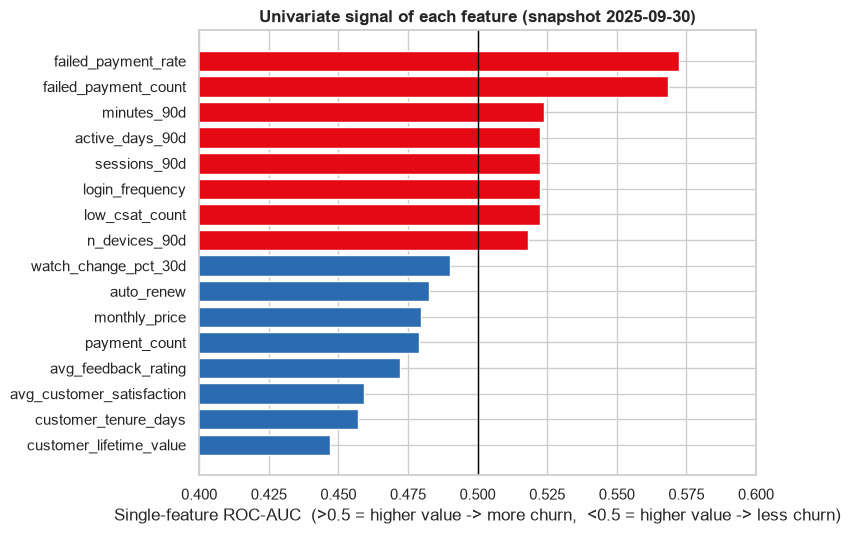

Strongest single signals: failed_payment_rate (0.572), failed_payment_count (0.569), customer_lifetime_value (0.553), customer_tenure_days (0.543), avg_customer_satisfaction (0.541)


In [6]:
from sklearn.metrics import roc_auc_score
num = snap.select_dtypes('number').drop(columns=['churned_next'])
auc = pd.Series({c: roc_auc_score(snap.churned_next, num[c].fillna(num[c].median())) for c in num.columns})
sig = (auc - .5).sort_values(); top = pd.concat([sig.head(8), sig.tail(8)])
fig, ax = plt.subplots(figsize=(8, 5.5)); ax.barh(top.index, top.values + .5, left=0, color=[BLUE if v < 0 else RED for v in top.values]); ax.axvline(.5, color='black', lw=1)
ax.set_xlim(.4, .6); ax.set_xlabel('Single-feature ROC-AUC  (>0.5 = higher value -> more churn,  <0.5 = higher value -> less churn)')
ax.set_title('Univariate signal of each feature (snapshot 2025-09-30)', fontweight='bold'); plt.tight_layout(); plt.savefig(FIG / '33_feature_univariate_auc.png', dpi=130, bbox_inches='tight'); plt.show()
print('Strongest single signals:', ', '.join(f'{k} ({v+.5:.3f})' for k, v in sig.abs().sort_values(ascending=False).head(5).items()))

## 6 · Why leakage matters: same model, two ways of building features
A quick gradient-boosting model, 5-fold CV ROC-AUC, **identical algorithm and features**: only the *timing* of the features differs.

In [7]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
cv = StratifiedKFold(5, shuffle=True, random_state=42)
mk = lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=.05, max_iter=150, random_state=0)
Xs = snap.select_dtypes('number').drop(columns=['churned_next']); Xl = full.select_dtypes('number').drop(columns=['churned'])
a_safe = cross_val_score(mk(), Xs, snap.churned_next, cv=cv, scoring='roc_auc').mean()
a_leak = cross_val_score(mk(), Xl, full.churned, cv=cv, scoring='roc_auc').mean()
print(f'Leakage-safe (features as of 2025-09-30, predict churn AFTER):  AUC = {a_safe:.3f}')
print(f'Leaky (features measured up to each exit date):                AUC = {a_leak:.3f}')
print(f'Inflation from leakage: +{a_leak - a_safe:.3f} AUC')

Leakage-safe (features as of 2025-09-30, predict churn AFTER):  AUC = 0.596
Leaky (features measured up to each exit date):                AUC = 0.711
Inflation from leakage: +0.115 AUC


## 7 · Save outputs

In [8]:
snap.to_csv(PROC / 'features_snapshot.csv', index=False)
full.to_csv(PROC / 'customer_features.csv', index=False)
dictionary.to_csv(PROC / 'feature_dictionary.csv', index=False)
print('saved features_snapshot.csv', snap.shape, '| customer_features.csv', full.shape)

saved features_snapshot.csv (7273, 42) | customer_features.csv (8000, 44)
